# Smart Electricity Consumption Analysis and Prediction

Software-only project using the Kaggle *Smart Meter Electricity Consumption Dataset* (ziya07).

**Pipeline:** preprocessing → descriptive statistics → correlation analysis → consumption patterns → regression → time-series forecasting → anomaly detection.

> **Note:** all numeric columns in this dataset are min-max scaled to 0-1, so values are *relative* consumption, not kWh. Install requirements with:
> `pip install numpy pandas matplotlib seaborn scikit-learn statsmodels`

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier, IsolationForest
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, classification_report, confusion_matrix

sns.set_theme(style="darkgrid")
pd.set_option("display.width", 150)

DATA_PATH = "smart_meter_data.csv"   # change if your file is elsewhere
df = pd.read_csv(DATA_PATH, parse_dates=["Timestamp"])
df.head()

,Timestamp,Electricity_Consumed,Temperature,Humidity,Wind_Speed,Avg_Past_Consumption,Anomaly_Label
0,2024-01-01 00:00:00,0.457786,0.469524,0.396368,0.445441,0.692057,Normal
1,2024-01-01 00:30:00,0.351956,0.465545,0.451184,0.458729,0.539874,Normal
2,2024-01-01 01:00:00,0.482948,0.285415,0.408289,0.470360,0.614724,Normal
3,2024-01-01 01:30:00,0.628838,0.482095,0.512308,0.576241,0.757044,Normal
4,2024-01-01 02:00:00,0.335974,0.624741,0.672021,0.373004,0.673981,Normal


## 1. Data preprocessing

In [2]:
print("Shape:", df.shape)
print("\nMissing values per column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate timestamps:", df["Timestamp"].duplicated().sum())

df = df.sort_values("Timestamp").reset_index(drop=True)
gaps = df["Timestamp"].diff().value_counts()
print("\nTime step between readings:\n", gaps)

num_cols = ["Electricity_Consumed", "Temperature", "Humidity", "Wind_Speed", "Avg_Past_Consumption"]
print("\nValue ranges:\n", df[num_cols].agg(["min", "max"]))

Shape: (5000, 7)

Missing values per column:
 Timestamp               0
Electricity_Consumed    0
Temperature             0
Humidity                0
Wind_Speed              0
Avg_Past_Consumption    0
Anomaly_Label           0
dtype: int64

Duplicate rows: 0
Duplicate timestamps: 0

Time step between readings:
 Timestamp
0 days 00:30:00    4999
Name: count, dtype: int64

Value ranges:
      Electricity_Consumed  Temperature  Humidity  Wind_Speed  Avg_Past_Consumption
min                   0.0          0.0       0.0         0.0                   0.0
max                   1.0          1.0       1.0         1.0                   1.0


In [ ]:
# Cleaning (applied defensively; this dataset needs little): interpolate gaps, drop duplicates
df = df.drop_duplicates(subset="Timestamp")
df[num_cols] = df[num_cols].interpolate(limit_direction="both")

# Time-based features
df["Hour"] = df["Timestamp"].dt.hour
df["DayOfWeek"] = df["Timestamp"].dt.dayofweek
df["Month"] = df["Timestamp"].dt.month
df["IsWeekend"] = (df["DayOfWeek"] >= 5).astype(int)
df["Anomaly"] = (df["Anomaly_Label"] == "Abnormal").astype(int)
ts = df.set_index("Timestamp")
df.head()

,Timestamp,Electricity_Consumed,Temperature,Humidity,Wind_Speed,Avg_Past_Consumption,Anomaly_Label,Hour,DayOfWeek,Month,IsWeekend,Anomaly
0,2024-01-01 00:00:00,0.457786,0.469524,0.396368,0.445441,0.692057,Normal,0,0,1,0,0
1,2024-01-01 00:30:00,0.351956,0.465545,0.451184,0.458729,0.539874,Normal,0,0,1,0,0
2,2024-01-01 01:00:00,0.482948,0.285415,0.408289,0.470360,0.614724,Normal,1,0,1,0,0
3,2024-01-01 01:30:00,0.628838,0.482095,0.512308,0.576241,0.757044,Normal,1,0,1,0,0
4,2024-01-01 02:00:00,0.335974,0.624741,0.672021,0.373004,0.673981,Normal,2,0,1,0,0


## 2. Descriptive statistics

In [6]:
display(df[num_cols].describe().T)
print("\nAnomaly label counts:\n", df["Anomaly_Label"].value_counts())
print("\nConsumption by label:")
display(df.groupby("Anomaly_Label")["Electricity_Consumed"].describe())

,count,mean,std,min,25%,50%,75%,max
Electricity_Consumed,5000.0,0.376677,0.164117,0.0,0.265349,0.377244,0.486002,1.0
Temperature,5000.0,0.525069,0.135603,0.0,0.434253,0.524052,0.617281,1.0
Humidity,5000.0,0.497632,0.146781,0.0,0.398956,0.497539,0.595359,1.0
Wind_Speed,5000.0,0.464628,0.120370,0.0,0.382906,0.464958,0.547419,1.0
Avg_Past_Consumption,5000.0,0.458738,0.146749,0.0,0.358857,0.457814,0.555607,1.0



Anomaly label counts:
 Anomaly_Label
Normal      4750
Abnormal     250
Name: count, dtype: int64

Consumption by label:


,count,mean,std,min,25%,50%,75%,max
Anomaly_Label,,,,,,,,
Abnormal,250.0,0.379039,0.319044,0.0,0.040996,0.322470,0.704768,1.000000
Normal,4750.0,0.376553,0.151706,0.0,0.270395,0.378035,0.481452,0.759653


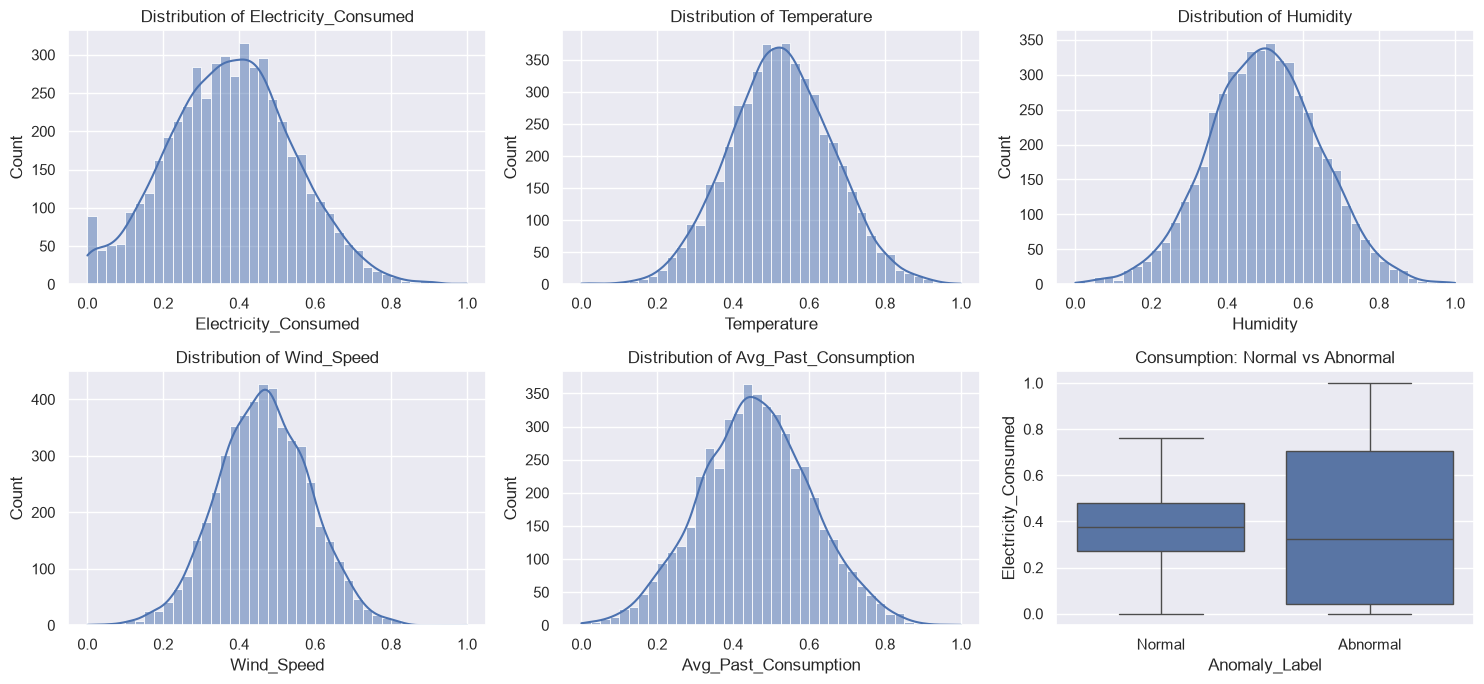

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], kde=True, ax=ax, bins=40)
    ax.set_title(f"Distribution of {col}")
sns.boxplot(data=df, x="Anomaly_Label", y="Electricity_Consumed", ax=axes[1, 2])
axes[1, 2].set_title("Consumption: Normal vs Abnormal")
plt.tight_layout(); plt.show()

## 3. Correlation analysis

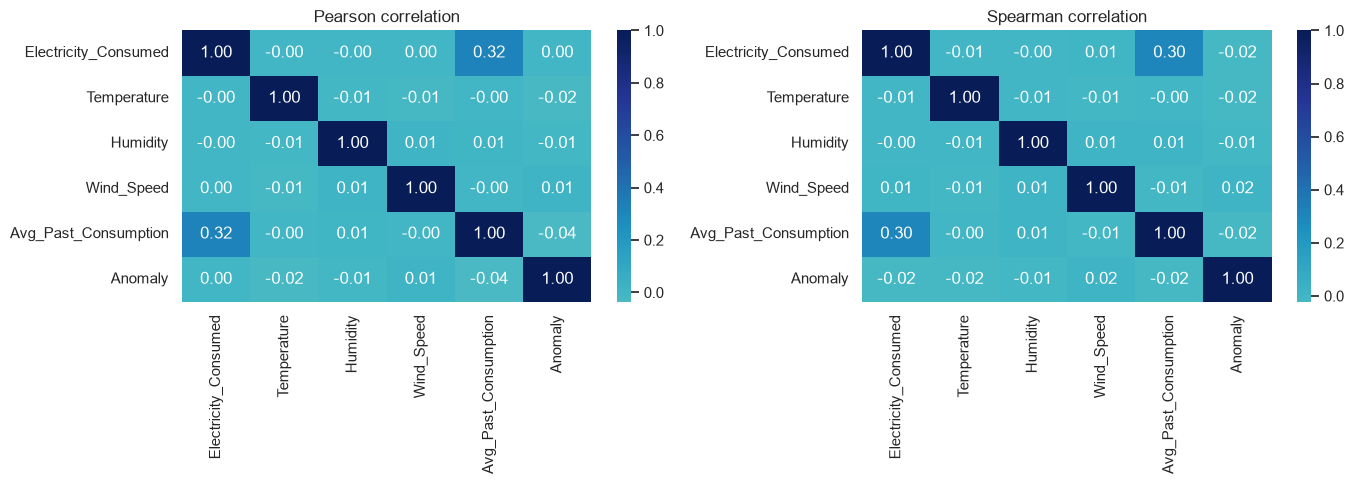

Avg_Past_Consumption    0.316663
Wind_Speed              0.001342
Humidity               -0.002916
Temperature            -0.003440
Name: Electricity_Consumed, dtype: float64


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = df[num_cols + ["Anomaly"]].corr(method=method)
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="YlGnBu", center=0, ax=ax)
    ax.set_title(f"{method.title()} correlation")
plt.tight_layout(); plt.show()

print(df[num_cols].corr()["Electricity_Consumed"].drop("Electricity_Consumed").sort_values(ascending=False))

**Interpretation:** only `Avg_Past_Consumption` shows a meaningful relationship with consumption (r ≈ 0.32). Temperature, humidity and wind speed are essentially uncorrelated (|r| < 0.01). This suggests the weather columns carry little predictive signal in this dataset.

## 4. Daily, weekly and monthly consumption patterns

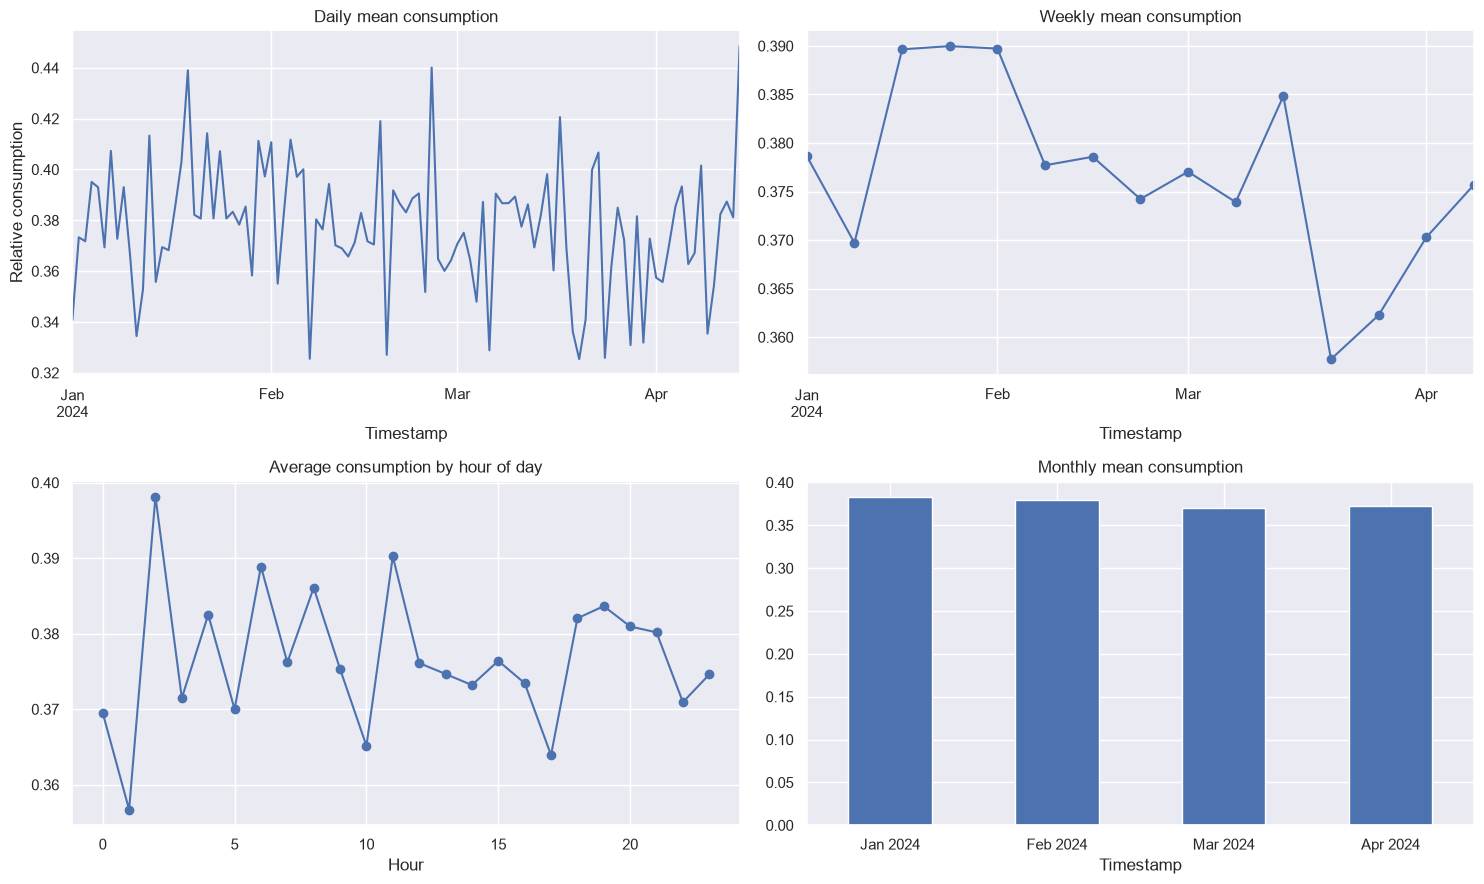

Mon    0.3736
Tue    0.3757
Wed    0.3661
Thu    0.3764
Fri    0.3852
Sat    0.3791
Sun    0.3809
Name: Electricity_Consumed, dtype: float64


In [29]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

ts["Electricity_Consumed"].resample("D").mean().plot(ax=axes[0, 0])
axes[0, 0].set_title("Daily mean consumption"); axes[0, 0].set_ylabel("Relative consumption")

ts["Electricity_Consumed"].resample("W").mean().plot(ax=axes[0, 1], marker="o")
axes[0, 1].set_title("Weekly mean consumption")

df.groupby("Hour")["Electricity_Consumed"].mean().plot(ax=axes[1, 0], marker="o")
axes[1, 0].set_title("Average consumption by hour of day"); axes[1, 0].set_xlabel("Hour")

ts["Electricity_Consumed"].resample("MS").mean().plot(kind="bar", ax=axes[1, 1])
axes[1, 1].set_title("Monthly mean consumption")
axes[1, 1].set_xticklabels([d.strftime("%b %Y") for d in ts["Electricity_Consumed"].resample("MS").mean().index], rotation=0)
plt.tight_layout(); plt.show()

dow = df.groupby("DayOfWeek")["Electricity_Consumed"].mean()
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print(dow.round(4))

**Observation:** consumption is nearly flat across hours, weekdays and months, so there is no strong daily or weekly seasonality. This is unusual compared with real household data and is consistent with a synthetic dataset.

## 5. Regression: predicting electricity consumption

Features: weather variables, `Avg_Past_Consumption`, calendar features, and lagged consumption. The split is **chronological** (first 80% train, last 20% test) so the model never sees the future.

In [38]:
feat = df.copy()
for lag in [1, 2, 48]:                       # 30 min, 1 h, 24 h earlier
    feat[f"Lag_{lag}"] = feat["Electricity_Consumed"].shift(lag)
feat["Roll_Mean_6"] = feat["Electricity_Consumed"].shift(1).rolling(6).mean()
feat = feat.dropna().reset_index(drop=True)

features = ["Temperature", "Humidity", "Wind_Speed", "Avg_Past_Consumption",
            "Hour", "DayOfWeek", "IsWeekend", "Lag_1", "Lag_2", "Lag_48", "Roll_Mean_6"]
target = "Electricity_Consumed"

split = int(len(feat) * 0.8)
X_train, X_test = feat.loc[:split-1, features], feat.loc[split:, features]
y_train, y_test = feat.loc[:split-1, target], feat.loc[split:, target]
print("Train:", X_train.shape, " Test:", X_test.shape)
#print(y_train, y_test)

Train: (3961, 11)  Test: (991, 11)


In [ ]:
models = {
    "Mean baseline": None,
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}
rows, preds = [], {}
for name, m in models.items(): 
    if m is None:
        p = np.full(len(y_test), y_train.mean())
    else:
        m.fit(X_train, y_train); p = m.predict(X_test)
    preds[name] = p
    rows.append({"Model": name,
                 "MAE": mean_absolute_error(y_test, p),
                 "RMSE": np.sqrt(mean_squared_error(y_test, p)),
                 "R2": r2_score(y_test, p)})
results = pd.DataFrame(rows).set_index("Model").round(4)
results

,MAE,RMSE,R2
Model,,,
Mean baseline,0.1304,0.1623,-0.0040
Linear Regression,0.1134,0.1416,0.2359
Ridge,0.1136,0.1420,0.2320
Random Forest,0.1173,0.1453,0.1952
Gradient Boosting,0.1155,0.1433,0.2175


Best model by RMSE: Linear Regression


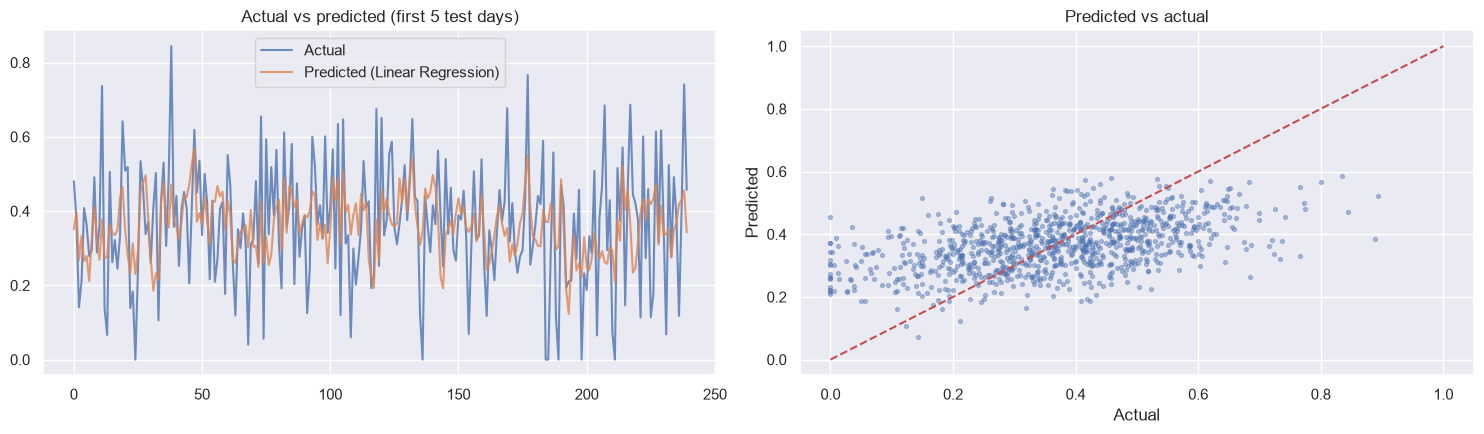

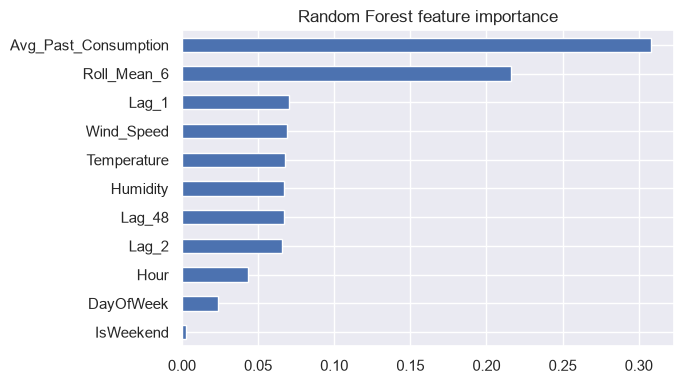

In [13]:
best = results.drop("Mean baseline")["RMSE"].idxmin()
print("Best model by RMSE:", best)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
n = 48 * 5   # first 5 days of the test set
axes[0].plot(y_test.values[:n], label="Actual", alpha=.8)
axes[0].plot(preds[best][:n], label=f"Predicted ({best})", alpha=.8)
axes[0].set_title("Actual vs predicted (first 5 test days)"); axes[0].legend()
axes[1].scatter(y_test, preds[best], s=8, alpha=.4)
axes[1].plot([0, 1], [0, 1], "r--"); axes[1].set_xlabel("Actual"); axes[1].set_ylabel("Predicted")
axes[1].set_title("Predicted vs actual")
plt.tight_layout(); plt.show()

rf = models["Random Forest"]
pd.Series(rf.feature_importances_, index=features).sort_values().plot(kind="barh", figsize=(7, 4), title="Random Forest feature importance")
plt.tight_layout(); plt.show()

**Interpretation:** compare each model with the *mean baseline*. A model with an R² near zero is barely better than predicting the average. Weak results here come from the data (little signal beyond `Avg_Past_Consumption`), not from a coding error.

## 6. Time-series analysis and forecasting

Requires `statsmodels`. We forecast the last 7 days (336 half-hour steps) and compare against a naive "same time yesterday" baseline.

ADF test p-value: 0.0 (p < 0.05 -> stationary)


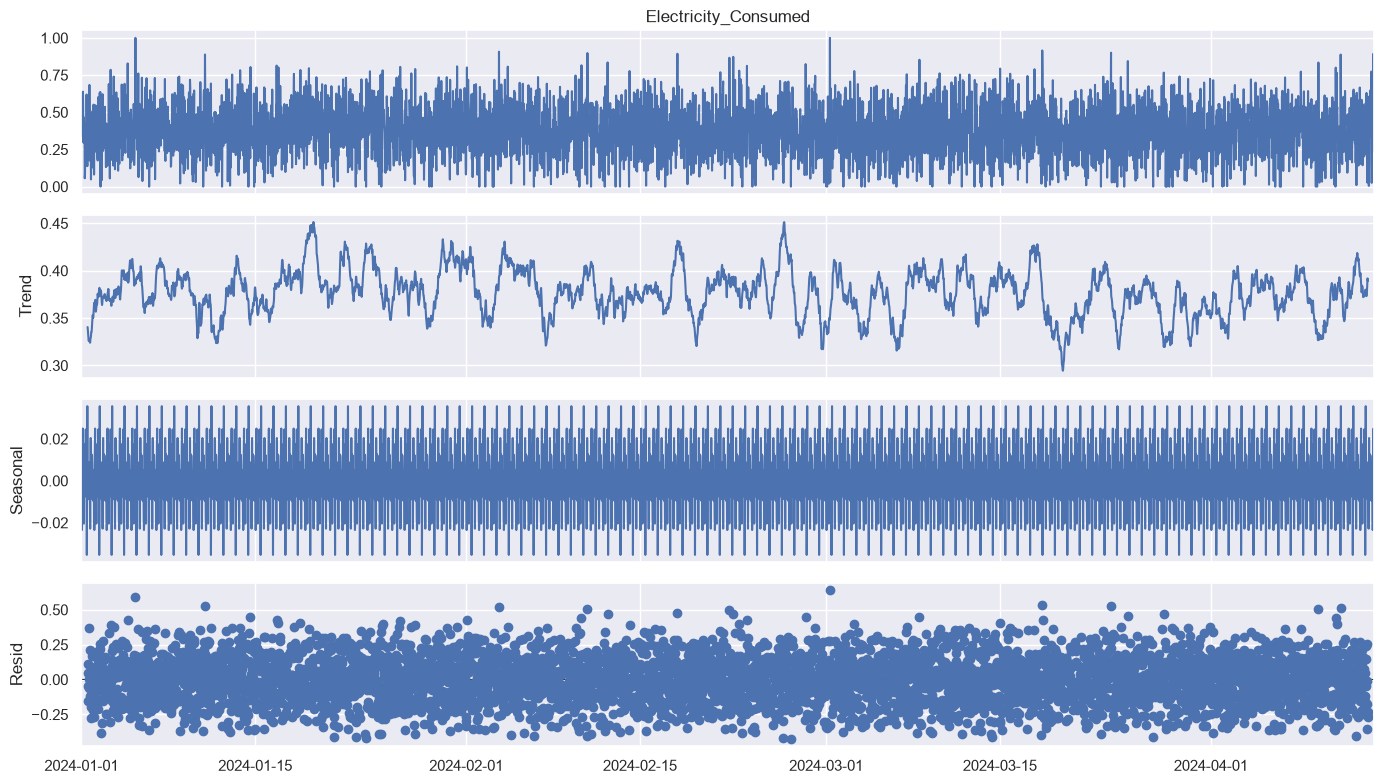

In [14]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller

series = ts["Electricity_Consumed"]
print("ADF test p-value:", round(adfuller(series)[1], 6), "(p < 0.05 -> stationary)")

dec = seasonal_decompose(series, model="additive", period=48)   # 48 half-hours = 1 day
fig = dec.plot(); fig.set_size_inches(14, 8); plt.tight_layout(); plt.show()

c:\Users\ITS Laptop\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency 30min will be used.
  self._init_dates(dates, freq)
c:\Users\ITS Laptop\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency 30min will be used.
  self._init_dates(dates, freq)
c:\Users\ITS Laptop\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency 30min will be used.
  self._init_dates(dates, freq)
c:\Users\ITS Laptop\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,MAE,RMSE
Model,,
"ARIMA(2,0,1)",0.1298,0.1633
Naive (yesterday),0.1875,0.2328
Mean baseline,0.1298,0.1633


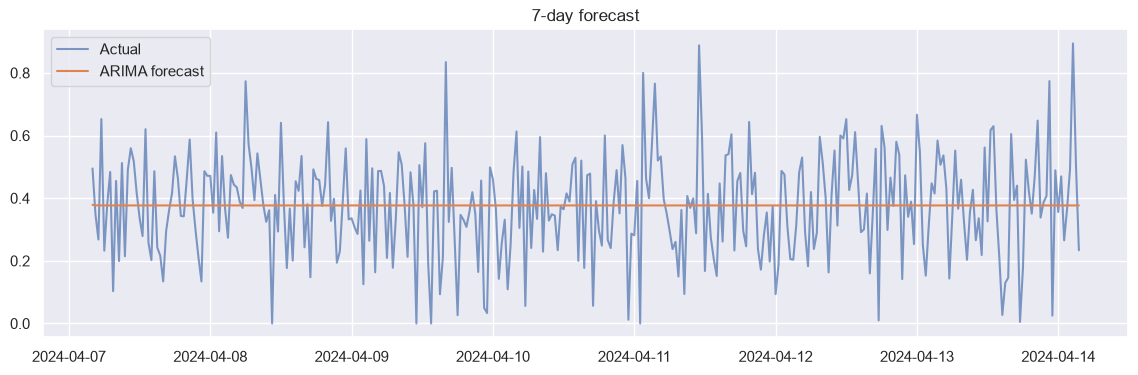

In [16]:
horizon = 48 * 7
train_ts, test_ts = series.iloc[:-horizon], series.iloc[-horizon:]

arima = ARIMA(train_ts, order=(2, 0, 1)).fit()
fc = arima.forecast(steps=horizon)
naive = series.shift(48).iloc[-horizon:]          # same time yesterday

def report(name, y, p):
    return {"Model": name, "MAE": mean_absolute_error(y, p), "RMSE": np.sqrt(mean_squared_error(y, p))}

ts_results = pd.DataFrame([
    report("ARIMA(2,0,1)", test_ts, fc.values),
    report("Naive (yesterday)", test_ts, naive.values),
    report("Mean baseline", test_ts, np.full(horizon, train_ts.mean())),
]).set_index("Model").round(4)
display(ts_results)

plt.figure(figsize=(14, 4))
plt.plot(test_ts.index, test_ts.values, label="Actual", alpha=.7)
plt.plot(test_ts.index, fc.values, label="ARIMA forecast")
plt.title("7-day forecast"); plt.legend(); plt.show()

## 7. Anomaly detection

The dataset includes labels (5% Abnormal), so we try both an **unsupervised** detector (Isolation Forest) and a **supervised** classifier. Accuracy is misleading here (always predicting "Normal" gives 95%), so we report precision, recall and F1.

=== Isolation Forest (unsupervised) ===
              precision    recall  f1-score   support

      Normal       0.96      0.97      0.97       944
    Abnormal       0.44      0.36      0.40        55

    accuracy                           0.94       999
   macro avg       0.70      0.67      0.68       999
weighted avg       0.93      0.94      0.94       999

=== Random Forest classifier (supervised) ===
              precision    recall  f1-score   support

      Normal       1.00      0.99      1.00       944
    Abnormal       0.88      0.96      0.92        55

    accuracy                           0.99       999
   macro avg       0.94      0.98      0.96       999
weighted avg       0.99      0.99      0.99       999



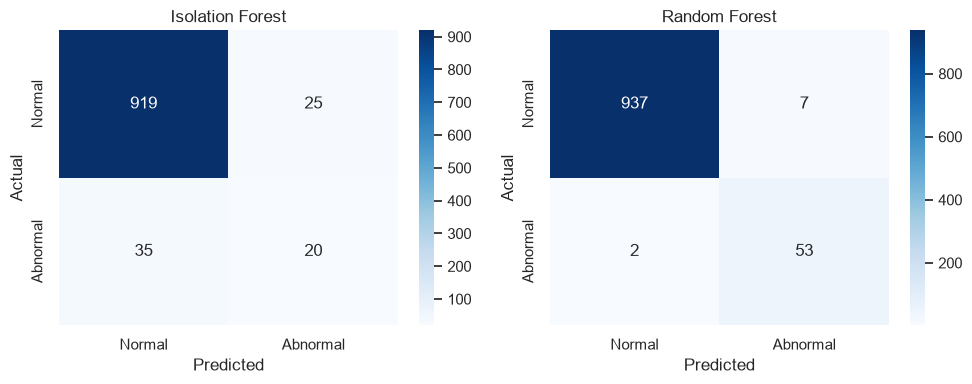

In [15]:
afeat = df.copy()
afeat["Lag_1"] = afeat["Electricity_Consumed"].shift(1)
afeat["Roll_Std_6"] = afeat["Electricity_Consumed"].rolling(6).std()
afeat["Diff_From_Avg"] = afeat["Electricity_Consumed"] - afeat["Avg_Past_Consumption"]
afeat = afeat.dropna().reset_index(drop=True)

acols = ["Electricity_Consumed", "Temperature", "Humidity", "Wind_Speed",
         "Avg_Past_Consumption", "Hour", "Lag_1", "Roll_Std_6", "Diff_From_Avg"]
asplit = int(len(afeat) * 0.8)
Xa_train, Xa_test = afeat.loc[:asplit-1, acols], afeat.loc[asplit:, acols]
ya_train, ya_test = afeat.loc[:asplit-1, "Anomaly"], afeat.loc[asplit:, "Anomaly"]

# Unsupervised
iso = IsolationForest(contamination=0.05, random_state=42).fit(Xa_train)
iso_pred = (iso.predict(Xa_test) == -1).astype(int)
print("=== Isolation Forest (unsupervised) ===")
print(classification_report(ya_test, iso_pred, target_names=["Normal", "Abnormal"], zero_division=0))

# Supervised
clf = RandomForestClassifier(n_estimators=300, class_weight="balanced", min_samples_leaf=3, random_state=42, n_jobs=-1)
clf.fit(Xa_train, ya_train)
clf_pred = clf.predict(Xa_test)
print("=== Random Forest classifier (supervised) ===")
print(classification_report(ya_test, clf_pred, target_names=["Normal", "Abnormal"], zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, p, t in zip(axes, [iso_pred, clf_pred], ["Isolation Forest", "Random Forest"]):
    sns.heatmap(confusion_matrix(ya_test, p), annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Normal", "Abnormal"], yticklabels=["Normal", "Abnormal"])
    ax.set_title(t); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

## 8. Conclusions

- **Data quality:** 5,000 half-hourly readings (Jan 1 - Apr 14, 2024), no missing values or duplicates.
- **Drivers of consumption:** `Avg_Past_Consumption` is the only meaningful predictor (r ≈ 0.32); weather variables show no correlation.
- **Patterns:** no strong hourly, weekly or monthly seasonality.
- **Prediction:** see the model comparison tables above; improvements over the mean baseline are modest.
- **Anomalies:** abnormal readings are mostly extreme high/low values; see the precision/recall tables for detection quality.
- **Limitations:** values are scaled and the data appears synthetic, so results should not be generalised to real consumption.
- **Future work:** real-world data with kWh units, holidays and occupancy features, LSTM models, and a Streamlit dashboard.